# LAB 2 — COUNTRY SCHOOLS DATASET
## Data Preprocessing, Anomaly Detection & Cluster Analysis 
**Course:** Computing Intelligence and Applications  
**Registration number:** 224004118  



## 1. Libraries and reproducibility
Pandas and NumPy manage data; Matplotlib/Seaborn create graphs; scikit-learn provides scaling, Isolation Forest, K-Means, and evaluation metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from IPython.display import display
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Dataset loading and description


In [2]:
from pathlib import Path
matches = list(Path('/kaggle/input').rglob('Country Schools.csv'))
if not matches:
    local_file = Path('/mnt/data/Country Schools.csv')
    if local_file.exists():
        matches = [local_file]
    else:
        raise FileNotFoundError('Attach Country Schools.csv as a Kaggle dataset first.')
file_path = matches[0]
print('Dataset path:', file_path)
raw = pd.read_csv(file_path)
print('Original shape:', raw.shape)
display(raw.head())
display(raw.tail())

Dataset path: /kaggle/input/datasets/kwizerayves/country-schools-record/Country Schools.csv
Original shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


**Observation — raw data:** The dataset contains 50 records and 8 attributes. The `PercentageInstalled` column is text because values contain `%`. The `TOTAL` row is a national aggregate and the final two rows have no county name; none of these three rows is a valid county observation.

## 3. Basic data preprocessing
### 3.1 Inspect types, nulls, duplicates and validity
We check for missing cells, duplicate rows, repeated county names, and inconsistent numeric fields **before** altering the source.

In [3]:
print('Column types:')
print(raw.dtypes)
print('\nMissing values per column:')
print(raw.isna().sum())
print('\nExact duplicate rows:', raw.duplicated().sum())
print('\nRepeated non-null county names:', raw.loc[raw['SNO'].notna(), 'SNO'].str.strip().str.upper().duplicated().sum())

Column types:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled       object
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object

Missing values per column:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

Exact duplicate rows: 0

Repeated non-null county names: 0


**Observation:** Two rows contain missing county information, although their `FID` values are present. These appear to be empty records rather than missing county measurements. Additionally, `PercentageInstalled` needs to be converted to a numeric format to ensure accurate calculations and analysis.

### 3.2 Remove non-county rows, convert percentages and verify totals


In [4]:
df = raw.copy()
df['SNO'] = df['SNO'].astype('string').str.strip().str.upper()
summary_rows = df['SNO'].eq('TOTAL').fillna(False)
blank_rows = df['SNO'].isna() | df['SNO'].eq('').fillna(False)
print('National total rows excluded:', summary_rows.sum())
print('Blank county rows excluded:', blank_rows.sum())
df = df.loc[~(summary_rows | blank_rows)].copy().reset_index(drop=True)
df['PercentageInstalled'] = pd.to_numeric(
    df['PercentageInstalled'].astype('string').str.rstrip('%'), errors='coerce'
)
numeric_cols = ['TOTALSCHOOLS','TotalSchoolsInstalled','SchoolsPending',
                'PercentageInstalled','InstalledLDDs','InstalledTDDs']
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
print('County dataset shape:', df.shape)
print('Missing values remaining:', int(df.isna().sum().sum()))
print('Unique counties:', df['SNO'].nunique())
print('Duplicate counties:', int(df['SNO'].duplicated().sum()))
print('Count identity mismatches:', int((df['TOTALSCHOOLS'] != df['TotalSchoolsInstalled'] + df['SchoolsPending']).sum()))
calculated_pct = 100 * df['TotalSchoolsInstalled'] / df['TOTALSCHOOLS']
print('Maximum percentage discrepancy (percentage points):', round((calculated_pct-df['PercentageInstalled']).abs().max(), 4))
display(df.head())

National total rows excluded: 1
Blank county rows excluded: 2
County dataset shape: (47, 8)
Missing values remaining: 0
Unique counties: 47
Duplicate counties: 0
Count identity mismatches: 0
Maximum percentage discrepancy (percentage points): 0.005


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


**Observation — Data Cleaning:**

After removing the national total and two empty rows, the dataset contains **47 counties** with no missing values or duplicates. All school totals are consistent, and minor percentage differences are due to rounding. Therefore, no additional data cleaning or imputation is required. Outliers are retained because they may represent important differences between counties that need further investigation.

### 3.3 Feature engineering and selection


In [5]:

df['PendingRate'] = 100 - df['PercentageInstalled']
df['LDDsPerInstalledSchool'] = np.where(df['TotalSchoolsInstalled'] > 0,
    df['InstalledLDDs'] / df['TotalSchoolsInstalled'], np.nan)
df['TDDsPerInstalledSchool'] = np.where(df['TotalSchoolsInstalled'] > 0,
    df['InstalledTDDs'] / df['TotalSchoolsInstalled'], np.nan)
print('Derived-feature missing values:', df[['PendingRate','LDDsPerInstalledSchool','TDDsPerInstalledSchool']].isna().sum().to_dict())
display(df[['SNO','TOTALSCHOOLS','PercentageInstalled','PendingRate',
            'LDDsPerInstalledSchool','TDDsPerInstalledSchool']].head())

Derived-feature missing values: {'PendingRate': 0, 'LDDsPerInstalledSchool': 0, 'TDDsPerInstalledSchool': 0}


,SNO,TOTALSCHOOLS,PercentageInstalled,PendingRate,LDDsPerInstalledSchool,TDDsPerInstalledSchool
0,TURKANA,358.0,10.34,89.66,101.189189,2.0
1,HOMA BAY,875.0,63.09,36.91,41.634058,2.0
2,WEST POKOT,498.0,48.59,51.41,62.454545,2.0
3,KITUI,1238.0,96.93,3.07,35.135000,2.0
4,TANA RIVER,159.0,89.94,10.06,51.853147,2.0


**Observation:**

Three additional features were created: pending installation rate, LDDs per installed school, and TDDs per installed school. These features help compare installation progress and device distribution across counties of different sizes. The FID column was excluded from modeling because it is only an identifier.

 All three new features were calculated successfully with no missing values. The results show differences in installation progress and device density across counties.

## 4. Exploratory Data Analysis (EDA)


,count,mean,std,min,25%,50%,75%,max
TOTALSCHOOLS,47.0,462.319149,254.204395,93.0,251.5,413.0,633.5,1238.0
TotalSchoolsInstalled,47.0,311.255319,228.997671,8.0,156.5,307.0,408.5,1200.0
SchoolsPending,47.0,151.06383,113.801009,4.0,52.5,130.0,243.0,448.0
PercentageInstalled,47.0,63.919149,25.847635,4.55,50.305,65.0,84.935,96.93
InstalledLDDs,47.0,15396.12766,11479.580532,606.0,6166.0,13507.0,22838.5,44338.0
InstalledTDDs,47.0,622.510638,457.995342,16.0,313.0,614.0,817.0,2400.0


Lowest installation rates:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled
30,MANDERA,198.0,9.0,4.55
36,WAJIR,211.0,11.0,5.21
38,MARSABIT,138.0,8.0,5.8
0,TURKANA,358.0,37.0,10.34
28,GARISSA,163.0,31.0,19.02
46,SAMBURU,146.0,49.0,33.56
35,NYERI,392.0,147.0,37.5
26,KERICHO,503.0,219.0,43.54


Highest installation rates:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled
3,KITUI,1238.0,1200.0,96.93
22,ELGEYO,369.0,354.0,95.93
14,LAMU,93.0,89.0,95.7
11,NANDI,709.0,673.0,94.92
24,KWALE,364.0,342.0,93.96
13,MAKUENI,887.0,833.0,93.91
10,NAROK,616.0,573.0,93.02
20,KILIFI,507.0,465.0,91.72


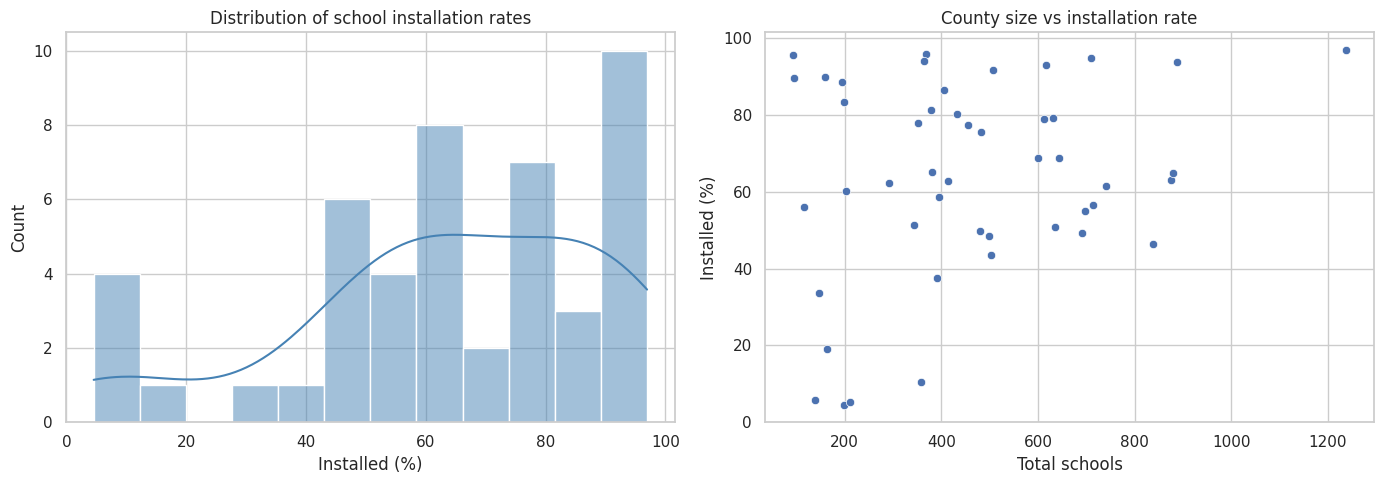

In [6]:
display(df[numeric_cols].describe().T.round(2))
print('Lowest installation rates:')
display(df.nsmallest(8,'PercentageInstalled')[['SNO','TOTALSCHOOLS','TotalSchoolsInstalled','PercentageInstalled']])
print('Highest installation rates:')
display(df.nlargest(8,'PercentageInstalled')[['SNO','TOTALSCHOOLS','TotalSchoolsInstalled','PercentageInstalled']])
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.histplot(df['PercentageInstalled'], bins=12, kde=True, ax=axes[0], color='steelblue')
axes[0].set(title='Distribution of school installation rates', xlabel='Installed (%)')
sns.scatterplot(data=df,x='TOTALSCHOOLS',y='PercentageInstalled',ax=axes[1])
axes[1].set(title='County size vs installation rate', xlabel='Total schools',ylabel='Installed (%)')
plt.tight_layout(); plt.show()

National school-weighted installation rate: 67.32%
Unweighted mean county rate: 63.92%
Lowest five installation rates:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled
30,MANDERA,198.0,9.0,4.55
36,WAJIR,211.0,11.0,5.21
38,MARSABIT,138.0,8.0,5.8
0,TURKANA,358.0,37.0,10.34
28,GARISSA,163.0,31.0,19.02


Highest five installation rates:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,PercentageInstalled
3,KITUI,1238.0,1200.0,96.93
22,ELGEYO,369.0,354.0,95.93
14,LAMU,93.0,89.0,95.7
11,NANDI,709.0,673.0,94.92
24,KWALE,364.0,342.0,93.96


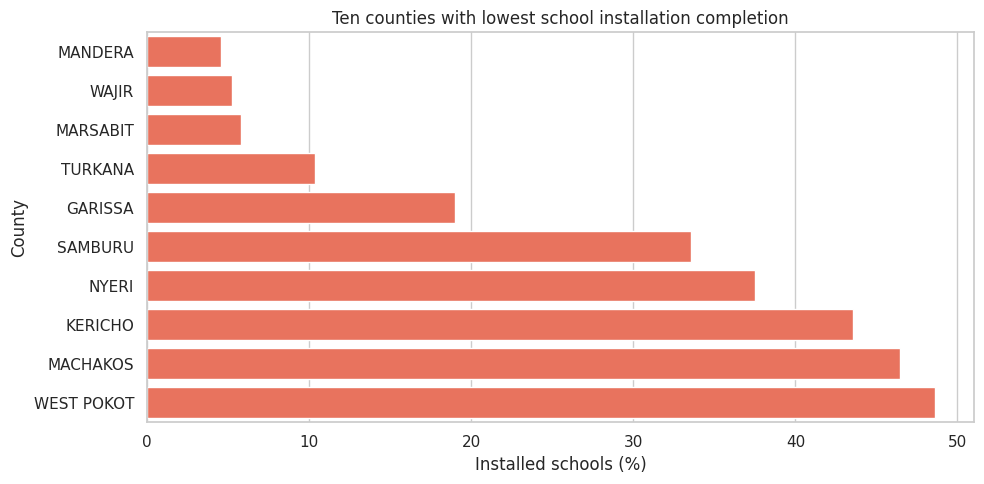

In [7]:
# Additional EDA: national weighted rate and top/bottom counties
weighted_pct = 100 * df['TotalSchoolsInstalled'].sum() / df['TOTALSCHOOLS'].sum()
print(f'National school-weighted installation rate: {weighted_pct:.2f}%')
print(f'Unweighted mean county rate: {df["PercentageInstalled"].mean():.2f}%')
print('Lowest five installation rates:')
display(df.nsmallest(5,'PercentageInstalled')[['SNO','TOTALSCHOOLS','TotalSchoolsInstalled','PercentageInstalled']])
print('Highest five installation rates:')
display(df.nlargest(5,'PercentageInstalled')[['SNO','TOTALSCHOOLS','TotalSchoolsInstalled','PercentageInstalled']])
plt.figure(figsize=(10,5))
sns.barplot(data=df.nsmallest(10,'PercentageInstalled'),x='PercentageInstalled',y='SNO',color='tomato')
plt.title('Ten counties with lowest school installation completion')
plt.xlabel('Installed schools (%)');plt.ylabel('County');plt.tight_layout();plt.show()

### 4.1 EDA Observations

The analysis shows significant differences in school installation progress across the 47 counties. Installation rates range from **4.55% in Mandera** to **96.93% in Kitui**, with an average county installation rate of **63.92%**. Mandera, Wajir, Marsabit, Turkana, and Garissa have the lowest installation rates, while Kitui, Elgeyo, Lamu, Nandi, and Kwale have the highest.

The national school-weighted installation rate is **67.32%**, slightly higher than the average county rate because counties with more schools contribute more to the national figure. The graphs also show differences in installation progress across counties of different sizes.

## 5. Anomaly detection
Anomaly detection is used to identify records that differ from others in a dataset. In this experiment, two methods are applied: Interquartile Range (IQR) and Isolation Forest. IQR identifies unusual values based on the distribution of installation percentages, while Isolation Forest detects unusual counties by analyzing several features together, such as the number of schools, installation completion, and device density. These methods help identify counties with unusual patterns for further investigation.

### 5.1 IQR analysis

Q1=50.30, Q3=84.94, IQR=34.63, lower=-1.64, upper=136.88
IQR anomaly count: 0


,SNO,PercentageInstalled,TOTALSCHOOLS


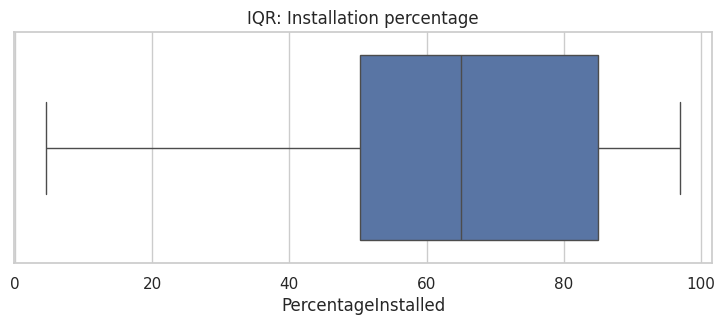

In [8]:
q1, q3 = df['PercentageInstalled'].quantile([0.25,0.75])
iqr = q3-q1
lower, upper = q1-1.5*iqr, q3+1.5*iqr
df['IQR_Anomaly'] = (df['PercentageInstalled'] < lower) | (df['PercentageInstalled'] > upper)
print(f'Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, lower={lower:.2f}, upper={upper:.2f}')
print('IQR anomaly count:', df['IQR_Anomaly'].sum())
display(df.loc[df['IQR_Anomaly'],['SNO','PercentageInstalled','TOTALSCHOOLS']].sort_values('PercentageInstalled'))
plt.figure(figsize=(9,3));sns.boxplot(x=df['PercentageInstalled']);plt.title('IQR: Installation percentage');plt.show()

**Result and interpretation:** The IQR rule flags **0 counties** on installation percentage alone. This does **not** mean all counties are typical in every respect; it means no county lies beyond the calculated univariate IQR fences.

### 5.2 Isolation Forest (Four Features)
Isolation Forest analyzes four transformed and standardized features, using a 10% contamination setting to flag five potentially unusual counties for further investigation.

Isolation Forest anomalies: 5


,SNO,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool,TDDsPerInstalledSchool,AnomalyScore
30,MANDERA,198.0,4.55,116.222222,2.0,-0.077210
0,TURKANA,358.0,10.34,101.189189,2.0,-0.059462
14,LAMU,93.0,95.7,34.640449,2.0,-0.022254
3,KITUI,1238.0,96.93,35.135000,2.0,-0.012672
38,MARSABIT,138.0,5.8,75.750000,2.0,-0.012181


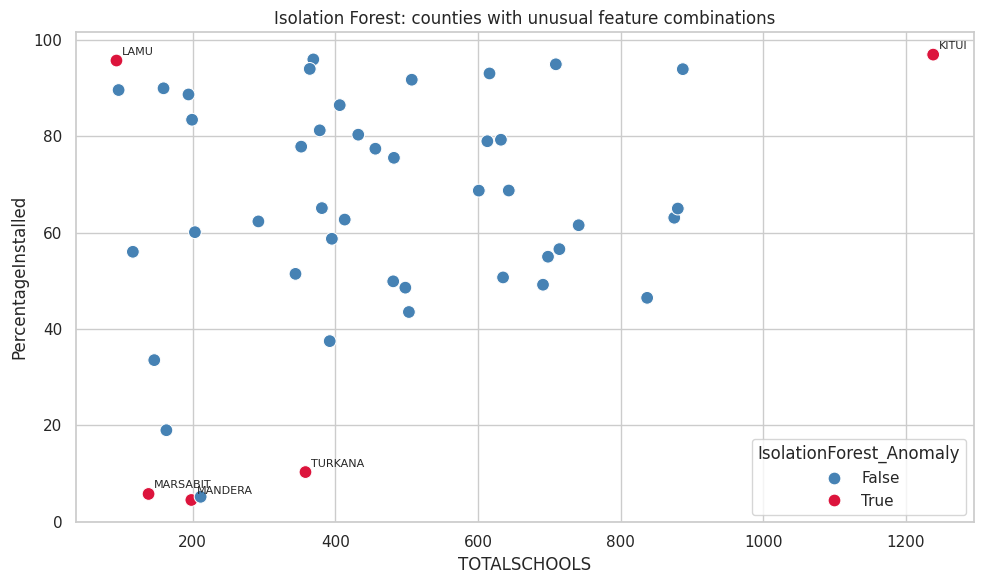

In [9]:
# Distinguish county size, installation completion, and device density.
iso_features = ['TOTALSCHOOLS','PercentageInstalled','LDDsPerInstalledSchool','TDDsPerInstalledSchool']
X_iso = df[iso_features].copy()
for c in ['TOTALSCHOOLS','LDDsPerInstalledSchool','TDDsPerInstalledSchool']:
    X_iso[c] = np.log1p(X_iso[c])
assert X_iso.notna().all().all(), 'Review missing values before fitting'
iso_scaler = StandardScaler()
X_iso_scaled = iso_scaler.fit_transform(X_iso)
model = IsolationForest(n_estimators=300, contamination=0.10, random_state=RANDOM_STATE)
df['IsolationForest_Label'] = model.fit_predict(X_iso_scaled)
df['IsolationForest_Anomaly'] = df['IsolationForest_Label'] == -1
df['AnomalyScore'] = model.decision_function(X_iso_scaled)
print('Isolation Forest anomalies:', int(df['IsolationForest_Anomaly'].sum()))
display(df.loc[df['IsolationForest_Anomaly'],
    ['SNO','TOTALSCHOOLS','PercentageInstalled','LDDsPerInstalledSchool',
     'TDDsPerInstalledSchool','AnomalyScore']].sort_values('AnomalyScore'))
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='TOTALSCHOOLS',y='PercentageInstalled',
    hue='IsolationForest_Anomaly',palette={False:'steelblue',True:'crimson'},s=85)
for _,r in df[df['IsolationForest_Anomaly']].iterrows():
    plt.annotate(r['SNO'],(r['TOTALSCHOOLS'],r['PercentageInstalled']),xytext=(4,4),textcoords='offset points',fontsize=8)
plt.title('Isolation Forest: counties with unusual feature combinations')
plt.tight_layout();plt.show()

**Observation:** Isolation Forest identified five unusual counties: **Mandera, Turkana, Lamu, Kitui, and Marsabit**, based on differences in school numbers, installation percentages, and device density. These results indicate unusual patterns that require further investigation.

### 5.3 Compare methods and sensitivity


In [10]:
print('Flagged by IQR:', int(df['IQR_Anomaly'].sum()))
print('Flagged by Isolation Forest:', int(df['IsolationForest_Anomaly'].sum()))
print('Flagged by both:', int((df['IQR_Anomaly'] & df['IsolationForest_Anomaly']).sum()))
display(df.loc[df['IQR_Anomaly'] | df['IsolationForest_Anomaly'],
    ['SNO','PercentageInstalled','IQR_Anomaly','IsolationForest_Anomaly','AnomalyScore']]
    .sort_values('AnomalyScore'))

Flagged by IQR: 0
Flagged by Isolation Forest: 5
Flagged by both: 0


,SNO,PercentageInstalled,IQR_Anomaly,IsolationForest_Anomaly,AnomalyScore
30,MANDERA,4.55,False,True,-0.077210
0,TURKANA,10.34,False,True,-0.059462
14,LAMU,95.7,False,True,-0.022254
3,KITUI,96.93,False,True,-0.012672
38,MARSABIT,5.8,False,True,-0.012181


In [11]:
# Sensitivity analysis: varying the assumed anomaly fraction
sensitivity=[]
for fraction in [0.05,0.10,0.15]:
    m=IsolationForest(n_estimators=300,contamination=fraction,random_state=RANDOM_STATE)
    labels=m.fit_predict(X_iso_scaled)
    names=sorted(df.loc[labels==-1,'SNO'].tolist())
    sensitivity.append({'Contamination':fraction,'Count':len(names),'Counties':', '.join(names)})
display(pd.DataFrame(sensitivity))

,Contamination,Count,Counties
0,0.05,3,"LAMU, MANDERA, TURKANA"
1,0.10,5,"KITUI, LAMU, MANDERA, MARSABIT, TURKANA"
2,0.15,7,"GARISSA, KITUI, LAMU, MANDERA, MARSABIT, NYERI..."


**Discussion:** 
Different methods answer different questions. IQR checks one dimension; Isolation Forest examines four dimensions. We also test how anomaly flags change under alternative contamination settings to show sensitivity.

When contamination changes, the number of flagged counties changes by design. Robust conclusions should emphasize counties that repeatedly appear under plausible settings, supported by domain-specific investigation. The absence of a known ground-truth anomaly label means we cannot calculate meaningful anomaly-detection accuracy, precision or recall.

## 6. Cluster Analysis Using K-Means



### 6.1 Compare candidate cluster counts

,k,inertia,silhouette,davies_bouldin
0,2,54.571,0.416,1.101
1,3,31.825,0.498,0.646
2,4,19.899,0.434,0.764
3,5,15.730,0.428,0.693
4,6,12.223,0.439,0.683
5,7,9.669,0.441,0.717
6,8,8.314,0.458,0.641


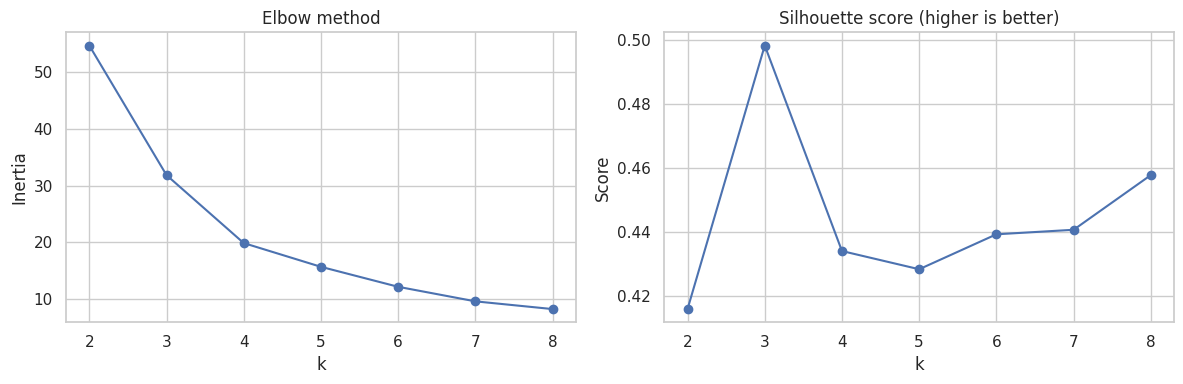

Best k by silhouette: 3


In [12]:
cluster_features = pd.DataFrame({
    'LogTotalSchools': np.log1p(df['TOTALSCHOOLS']),
    'PercentageInstalled': df['PercentageInstalled']
})
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(cluster_features)
results = []
for k in range(2,9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_cluster)
    results.append({'k':k,'inertia':km.inertia_,
                    'silhouette':silhouette_score(X_cluster,labels),
                    'davies_bouldin':davies_bouldin_score(X_cluster,labels)})
metrics = pd.DataFrame(results)
display(metrics.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(metrics['k'],metrics['inertia'],'o-');axes[0].set(title='Elbow method',xlabel='k',ylabel='Inertia')
axes[1].plot(metrics['k'],metrics['silhouette'],'o-');axes[1].set(title='Silhouette score (higher is better)',xlabel='k',ylabel='Score')
plt.tight_layout();plt.show()
best_k = int(metrics.loc[metrics['silhouette'].idxmax(),'k'])
print('Best k by silhouette:',best_k)

**Finding:** The highest silhouette score among the tested values occurs at **k = 3** (silhouette ≈ **0.498**). The elbow plot provides a visual check on whether additional clusters materially improve compactness. This notebook uses the silhouette-selected value for reproducibility.

### 6.2 Cluster membership, characteristics and visualization

Cluster profiles:


,Counties,MeanTotalSchools,MeanInstalledPct,MeanPending,MeanLDDsPerInstalledSchool
Cluster,,,,,
0,34,572.21,69.48,171.00,48.68
1,7,151.43,80.49,31.00,50.76
2,6,202.33,13.08,178.17,80.08


Counties in each cluster:
Cluster 0: NYERI, KERICHO, MACHAKOS, WEST POKOT, NAKURU, KIAMBU, BARINGO, NYANDARUA, KISII, MERU, KAJIADO, BUNGOMA, LAIKIPIA, THARAKA NITHI, HOMA BAY, KAKAMEGA, EMBU, MIGORI, SIAYA, MURANG'A, UASIN GISHU, TRANS NZOIA, KISUMU, BOMET, BUSIA, VIHIGA, NYAMIRA, KILIFI, NAROK, MAKUENI, KWALE, NANDI, ELGEYO, KITUI
Cluster 1: ISIOLO, NAIROBI, KIRINYAGA, TAITA TAVETA, MOMBASA, TANA RIVER, LAMU
Cluster 2: MANDERA, WAJIR, MARSABIT, TURKANA, GARISSA, SAMBURU


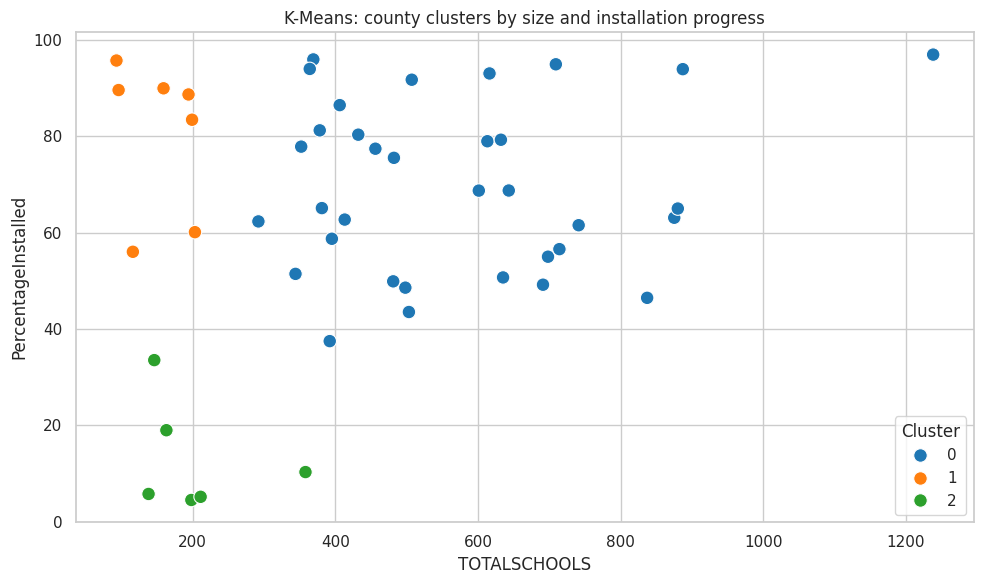

In [13]:
kmeans = KMeans(n_clusters=best_k,random_state=RANDOM_STATE,n_init=20)
df['Cluster'] = kmeans.fit_predict(X_cluster)
profiles = df.groupby('Cluster').agg(
    Counties=('SNO','count'),
    MeanTotalSchools=('TOTALSCHOOLS','mean'),
    MeanInstalledPct=('PercentageInstalled','mean'),
    MeanPending=('SchoolsPending','mean'),
    MeanLDDsPerInstalledSchool=('LDDsPerInstalledSchool','mean')
).round(2)
print('Cluster profiles:')
display(profiles)
print('Counties in each cluster:')
for cluster_id,grp in df.groupby('Cluster'):
    print(f'Cluster {cluster_id}:', ', '.join(grp.sort_values('PercentageInstalled')['SNO']))
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='TOTALSCHOOLS',y='PercentageInstalled',hue='Cluster',
               palette='tab10',s=95)
plt.title('K-Means: county clusters by size and installation progress')
plt.tight_layout();plt.show()

**Cluster 0 — verified profile:** **34 counties**; mean installation completion **69.48%**; mean total schools **572.2**. Counties: NYERI, KERICHO, MACHAKOS, WEST POKOT, NAKURU, KIAMBU, BARINGO, NYANDARUA, KISII, MERU, KAJIADO, BUNGOMA, LAIKIPIA, THARAKA NITHI, HOMA BAY, KAKAMEGA, EMBU, MIGORI, SIAYA, MURANG'A, UASIN GISHU, TRANS NZOIA, KISUMU, BOMET, BUSIA, VIHIGA, NYAMIRA, KILIFI, NAROK, MAKUENI, KWALE, NANDI, ElGEYO , KITUI.

Interpret this as a group defined by **both size and completion**. Cluster numbers are arbitrary labels, not performance rankings. Compare the mean completion and mean size with the other clusters before naming the group.

**Cluster 1 — verified profile:** **7 counties**; mean installation completion **80.49%**; mean total schools **151.4**. Counties: ISIOLO, NAIROBI, KIRINYAGA, TAITA TAVETA, MOMBASA, TANA RIVER, LAMU.

Interpret this as a group defined by **both size and completion**. Cluster numbers are arbitrary labels, not performance rankings. Compare the mean completion and mean size with the other clusters before naming the group.

**Cluster 2 — verified profile:** **6 counties**; mean installation completion **13.08%**; mean total schools **202.3**. Counties: MANDERA, WAJIR, MARSABIT, TURKANA, GARISSA, SAMBURU.

Interpret this as a group defined by **both size and completion**. Cluster numbers are arbitrary labels, not performance rankings. Compare the mean completion and mean size with the other clusters before naming the group.

### 6.3 Validate clusters and examine anomaly overlap

In [14]:
print('Final silhouette score:',round(silhouette_score(X_cluster,df['Cluster']),3))
print('Final Davies-Bouldin index:',round(davies_bouldin_score(X_cluster,df['Cluster']),3))
print('Isolation Forest anomaly counts per cluster:')
display(pd.crosstab(df['Cluster'],df['IsolationForest_Anomaly'],
                    rownames=['Cluster'],colnames=['Is anomaly']))
print('Cluster installation summaries:')
display(df.groupby('Cluster')['PercentageInstalled'].agg(['min','median','mean','max']).round(2))

Final silhouette score: 0.498
Final Davies-Bouldin index: 0.646
Isolation Forest anomaly counts per cluster:


Is anomaly,False,True
Cluster,,
0,33,1
1,6,1
2,3,3


Cluster installation summaries:


,min,median,mean,max
Cluster,,,,
0,37.5,66.9,69.48,96.93
1,56.03,88.66,80.49,95.7
2,4.55,8.07,13.08,33.56


Average silhouette per cluster:


,mean,min,max
Cluster,,,
0,0.476,0.054,0.654
1,0.491,0.260,0.639
2,0.633,0.386,0.769


Counties with weak/negative silhouette:


,SNO,Cluster,PercentageInstalled,TOTALSCHOOLS,SilhouetteSample
35,NYERI,0,37.5,392.0,0.053925
29,LAIKIPIA,0,62.33,292.0,0.120946
22,ELGEYO,0,95.93,369.0,0.190332
24,KWALE,0,93.96,364.0,0.195834
40,NAIROBI,1,60.1,203.0,0.260456
32,ISIOLO,1,56.03,116.0,0.285870
23,TRANS NZOIA,0,77.84,352.0,0.305310
37,NYANDARUA,0,51.45,344.0,0.336563


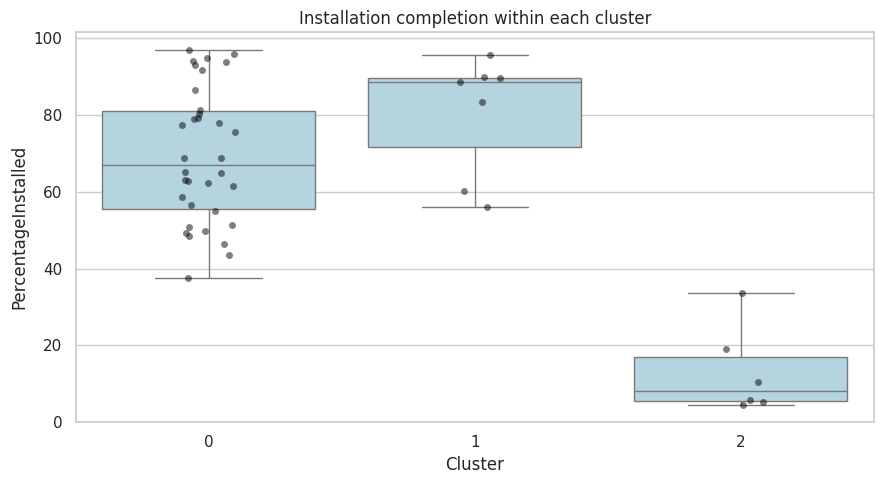

In [15]:
# Optional diagnostic: silhouette score for each county
from sklearn.metrics import silhouette_samples
from sklearn.decomposition import PCA
scores_by_county = silhouette_samples(X_cluster,df['Cluster'])
df['SilhouetteSample'] = scores_by_county
print('Average silhouette per cluster:')
display(df.groupby('Cluster')['SilhouetteSample'].agg(['mean','min','max']).round(3))
print('Counties with weak/negative silhouette:')
display(df.nsmallest(8,'SilhouetteSample')[['SNO','Cluster','PercentageInstalled','TOTALSCHOOLS','SilhouetteSample']])
plt.figure(figsize=(9,5))
sns.boxplot(data=df,x='Cluster',y='PercentageInstalled',color='lightblue')
sns.stripplot(data=df,x='Cluster',y='PercentageInstalled',color='black',alpha=.5)
plt.title('Installation completion within each cluster')
plt.tight_layout();plt.show()

**Interpretation:** A high overall silhouette indicates better average separation, while negative county-level silhouettes indicate observations closer to another cluster than their assigned cluster. Davies–Bouldin summarizes compactness versus separation; smaller values are preferable. Isolation Forest anomalies may occur in any cluster, because *unusualness* and *group membership* are different concepts.

## 7. Findings and Discussion

### 7.1 Findings

After data cleaning, **47 counties** remained with no missing values or duplicates. The IQR method detected no outliers in installation percentages, while Isolation Forest identified **five unusual counties: Mandera, Turkana, Lamu, Kitui, and Marsabit**. K-Means clustering divided the counties into **three groups** based on school numbers and installation progress.

### 7.2 Limitations

The analysis is based on only 47 counties and does not include information about budgets, infrastructure, or installation dates. Therefore, the results identify patterns but cannot explain their causes.

### 7.3 Recommendations

The five identified counties should be investigated further to understand their unusual characteristics. Cluster results can also help compare counties with similar installation progress. Additional data would improve future analysis.



